# Upstream FDI — River Corridors (DPWMS / GEDH Module 1)

Guinea Environmental Digital Hub, Digital Plastic Waste Management System.

The coastal floating-debris layer covers five coastal boxes. Two of them, Konkouré and Fatala, are
river *mouths* (`embouchure`), so the coastal layer reaches the estuaries and nothing upstream. The
concept note asks for accumulation on the coast **and in rivers**.

This notebook extends the same detector upstream — the FDI-and-NDVI rule, then the MARIDA debris
classifier — over corridors built around Guinea's river network, and records what can and cannot be
assessed there.

| step | script | what it does |
|---|---|---|
| 1 | `29_prepare_river_corridors.py` | build corridor AOIs from HydroRIVERS, tiled for fetching |
| 2 | `30_run_river_fdi.py --preflight` | count real mapped water per tile — **free** |
| 3 | `30_run_river_fdi.py` | run the detector on the tiles that can be assessed |

**Step 2 costs nothing and should never be skipped.** It decides which tiles can carry a threshold
before any imagery is fetched.

**Result for January 2024:** 49 tiles (3,295 km, 55% of the screened corridor length) are assessed,
and the published layer has **no patches** on them. The river thresholds run 1.2× the coastal one, so
upstream sensitivity is lower than on the coast; section 5 explains why that zero is not evidence of a
clean river.

> **The detector this notebook runs.** The FDI follows Biermann et al. (2020, eq. 1–2): NIR = **B8**,
> RE2 = **B6**, SWIR1 = **B11**, with the **B4 (red)** wavelength in the interpolation ratio. A pixel is
> published when FDI and NDVI exceed mean + 3σ of the tile's water pixels and the MARIDA debris
> classifier gives it P(debris) ≥ 0.5 — the same sequence as the coastal layer.
>
> The results file records the detector id (`fdi_tool.debris_filter.detector_id()`), and `--resume`
> only reuses tiles run with the same detector. Results from the version before October 2026 (B8A in
> place of B6, no classifier) are therefore never mixed with these.

In [1]:
# torch MUST initialise before the GDAL/GEE stack on Windows: both ship native
# DLLs and whichever loads first wins. Without this, importing torch after
# geopandas fails with WinError 1114.
import torch  # noqa: F401

import json, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd()
TOOL = ROOT / "plasticwaste_tool"
MQ   = TOOL / "manual_qa"
RUNS = MQ / "runs" / "river_fdi"
RIV  = TOOL / "data" / "rivers"
assert TOOL.exists(), f"run this notebook from the folder containing plasticwaste_tool/ (cwd={ROOT})"

def run(args, timeout=7200):
    '''Call a pipeline script and stream its output.'''
    cmd = [sys.executable] + args
    print("$", " ".join(str(c) for c in cmd), flush=True)
    p = subprocess.run(cmd, cwd=TOOL, capture_output=True, text=True, timeout=timeout)
    print(p.stdout[-8000:])
    if p.returncode != 0:
        print("STDERR:", p.stderr[-3000:])
    return p

print("ready")

ready


## 1. Why corridors instead of bounding boxes

The FDI threshold is **mean + 3σ over the water population of whatever area is analysed**. Draw a
rectangle over a river and it is mostly land, so the water population is small, σ is estimated from
too few pixels, and the threshold is meaningless. A coastal box drawn too far inland shows the same
failure: the pipeline refuses to call it assessed.

A **corridor** — a buffer around the river centreline — confines the analysis to where water actually
is.

### Which rivers are kept, and why

Only rivers Sentinel-2 can resolve. Width is estimated from discharge using the global
hydraulic-geometry relation of Andreadis et al. (2013), *w = 7.2·Q^0.5*:

| discharge | est. width | Sentinel-2 pixels |
|---|---|---|
| 10 m³/s | ~23 m | 2.3 |
| **25 m³/s** | **~36 m** | **3.6** ← the cut |
| 50 m³/s | ~51 m | 5.1 |
| 100 m³/s | ~72 m | 7.2 |

Below ~3 pixels, mixed land–water edge pixels dominate the channel and the "water population" is not
really water.

*Takes ~8 minutes: it reads a 237 MB continental shapefile. Skipped if `data/rivers/` already exists.*

### Why each river system is split into tiles

A raster export is rectangular whatever geometry is passed to it, and a winding river's bounding box
is mostly empty land. Across Guinea's 20 systems the corridor-to-bounding-box ratio runs **10–300×**;
one 203 km² corridor would need a 61,772 km² fetch, and one box per system would mean compositing
**252,497 km²** — more than the area of Guinea.

So reaches (median 2.5 km) are grouped into **tiles** by snapping each reach's centroid to a grid
sized so a filled cell is about the size of a coastal AOI (~2,500 km²). A winding river becomes a
*chain* of small tiles along its path. The total fetch is **80,752 km²** — still more than the corridor
area, because each tile covers its own local bounding box, but every individual fetch is bounded to
coastal-AOI scale.

**Trade-off, stated plainly:** each *tile* gets its own threshold, not each *system*. A river split
into nine tiles has nine independently derived thresholds rather than one pooled estimate. Pooling
would be more statistically efficient; it needs `run_from_arrays` to accept a pre-computed threshold,
which is a documented next step (`29_prepare_river_corridors.py`), not something done here.

In [2]:
if not (RIV / "river_aois.json").exists():
    run(["29_prepare_river_corridors.py"])
else:
    print(f"corridors already built in {RIV} — delete the folder to rebuild")

meta = json.loads((RIV / "river_aois.json").read_text(encoding="utf-8"))
print(f"\n{meta['n_systems']} river systems -> {meta.get('n_tiles', 0)} fetchable tiles, "
      f"{meta['total_length_km']:,.0f} km, "
      f"{meta['total_corridor_km2']:,.0f} km2 of corridor, "
      f"{meta.get('total_fetch_bbox_km2', 0):,.0f} km2 of actual fetch area")

corridors already built in c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\plasticwaste_tool\data\rivers — delete the folder to rebuild

20 river systems -> 117 fetchable tiles, 5,972 km, 2,864 km2 of corridor, 80,752 km2 of actual fetch area


## 2. The water-population guard for corridors

HydroRIVERS centrelines come from HydroSHEDS at 15 arc-seconds, roughly **500 m at this latitude**, so a
centreline can sit a few hundred metres from the real channel. The buffer is therefore ±250 m, to be
sure of containing it.

A 36 m river inside a 500 m corridor is only **~7% water** — below the 10% `min_water_fraction` guard
used for coastal boxes, even though the corridor is doing exactly its job.

> **Water fraction is the wrong statistic for a river.**

What makes a mean+3σ threshold trustworthy is the **number** of pixels behind it. The relative standard
error of a standard deviation is ≈ 1/√(2n):

| n | rel. SE of σ |
|---|---|
| 100 | 7.1% |
| 500 | 3.2% |
| **1000** | **2.2%** ← the floor |

So `config.DETECTION_CONFIG` sets an absolute **`min_water_px = 1000`**, and corridors are passed
`aoi_kind="river_corridor"` so the fraction guard is advisory for them. The logic is in
`fdi_tool.pipeline.assess_water_population`, separate so it can be tested without a raster stack:

In [3]:
from plasticwaste_tool.fdi_tool.pipeline import assess_water_population as assess

cases = [("coastal, plenty of water",      150_000, 250_000, None),
         ("coastal box misplaced (Fatala)",   5_000, 250_000, None),
         ("river corridor, 7% but large",    17_500, 250_000, "river_corridor"),
         ("river corridor, tiny stream",        700,  10_000, "river_corridor"),
         ("small AOI, 67% water, 400 px",       400,     600, None)]

pd.DataFrame([{
    "case": lbl,
    "water_fraction": round(assess(w, t, k)["water_fraction"], 3),
    "water_px": f"{w:,}",
    "fails_fraction": assess(w, t, k)["low_water_fraction"],
    "fails_count": assess(w, t, k)["low_water_count"],
    "verdict": "assessed" if assess(w, t, k)["assessed"] else "NOT assessed",
} for lbl, w, t, k in cases])

,case,water_fraction,water_px,fails_fraction,fails_count,verdict
0,"coastal, plenty of water",0.600,"150,000",False,False,assessed
1,coastal box misplaced (Fatala),0.020,"5,000",True,False,NOT assessed
2,"river corridor, 7% but large",0.070,"17,500",True,False,assessed
3,"river corridor, tiny stream",0.070,700,True,True,NOT assessed
4,"small AOI, 67% water, 400 px",0.667,400,False,True,NOT assessed


Reading the five cases:

- **Coastal box misplaced (Fatala)** — 2% water because it is mostly land: refused, correctly. The
  Fatala *river* is covered by its corridor instead.
- **River corridor, 7% but large** — fails the fraction test but carries an ample population:
  assessed.
- **River corridor, tiny stream** — too few water pixels for a stable σ: refused.
- **Small AOI, 67% water, 400 px** — mostly water but too few pixels: refused by the count floor, which
  a fraction test alone would have passed.

---

## 3. Preflight — free, and the step that decides what can be assessed

`est_water_px` from step 1 is **geometry**: channel width from discharge, times length, divided by
pixel size. It says what a river of that size *ought* to present.

What the pipeline actually sees is **ESA WorldCover class 80, "permanent water bodies"**, resampled to
the 20 m download scale, minus a 20 m dilation around built-up land. Those two numbers diverge — badly.

This counts the **real** mapped water per tile with one server-side `reduceRegion` each. **No imagery is
fetched and nothing is billed.**

In [4]:
run(["30_run_river_fdi.py", "--preflight"])

$ c:\Users\ASUS\AppData\Local\Programs\Python\Python310\python.exe 30_run_river_fdi.py --preflight
r_10558276_t02       98     66,645     13,362    0.20    assessable
    river_10794161_t02       98     66,246      4,698    0.07    assessable
    river_10558276_t06       97     61,540     12,686    0.21    assessable
    river_10428478_t05       96     30,841      5,545    0.18    assessable
    river_10428478_t04       95     83,751     12,790    0.15    assessable
    river_10558276_t05       95    114,281     25,715    0.23    assessable
    river_10588694_t05       92     77,696      5,121    0.07    assessable
    river_10558276_t08       90     12,788      2,655    0.21    assessable
    river_10877687_t17       90     98,210     12,705    0.13    assessable
    river_10877687_t14       89    116,136      5,308    0.05    assessable
    river_10794161_t04       86     60,204      1,300    0.02    assessable
    river_10877687_t20       85     56,497      6,512    0.12    assessab

CompletedProcess(args=['c:\\Users\\ASUS\\AppData\\Local\\Programs\\Python\\Python310\\python.exe', '30_run_river_fdi.py', '--preflight'], returncode=0, stdout='Counting WorldCover water pixels at 20 m, floor = 1,000 px\n\n               aoi key  width m     est px  actual px   ratio       verdict\n    river_10877687_t30      206    135,193     41,536    0.31    assessable\n    river_10877687_t23      204    198,196     47,710    0.24    assessable\n    river_10633048_t01      182     64,310     15,325    0.24    assessable\n    river_10877687_t22      181    247,061     80,194    0.32    assessable\n    river_10633048_t03      178    173,519     16,691    0.10    assessable\n    river_10877687_t16      147    210,509     50,563    0.24    assessable\n    river_10877687_t21      147    123,747     10,500    0.08    assessable\n    river_10633048_t04      140     82,724     29,816    0.36    assessable\n    river_10877687_t35      133     24,179      4,314    0.18    assessable\n    rive

### Reading that table

The `ratio` column is actual ÷ estimated water, and its median is **0.05**: WorldCover maps far less
water than channel geometry predicts, even for the largest rivers. Two reasons, both real rather than
bugs:

1. **WorldCover is a land-cover product.** Narrow and seasonal rivers are frequently not classified as
   *permanent* water at all.
2. **January is Guinea's dry season**, and the download scale is 20 m — so a 46 m channel is about two
   pixels wide before the built-up erosion touches it.

A tile below the 1,000-pixel floor is reported NOT ASSESSED.

> **NOT ASSESSED means "could not look", never "nothing there".** It must never be rendered as a
> clean river.

**Coverage:** **65 of 117 tiles** pass the preflight — **4,422 of 5,972 km (74%)** of river length.
**Five systems have no assessable tile**: WorldCover maps no part of those channels as permanent water
at the download scale. They are the smallest systems (20–118 km), consistent with the dry-season,
narrow-channel explanation. This is a limit of the water product, not of the guard, and it bounds how
far upstream the layer can honestly go.

The preflight over all 117 tiles takes under three minutes.

In [5]:
pf = json.loads((RUNS / "river_preflight.json").read_text(encoding="utf-8"))
df = pd.DataFrame(pf["rows"])
df["ratio"] = (df["actual_water_px"] / df["est_water_px"]).round(3)
ok = df[df["would_assess"]]
print(f"{len(ok)}/{len(df)} tiles assessable "
      f"({ok['length_km'].sum():,.0f} of {df['length_km'].sum():,.0f} km, "
      f"{ok['length_km'].sum() / df['length_km'].sum():.0%})")
print(f"median actual/estimated water ratio: {df['ratio'].median():.2f}")

by_sys = df.groupby("main_riv").agg(
    tiles=("aoi", "count"),
    tiles_ok=("would_assess", "sum"),
    km=("length_km", "sum"),
)
zero = by_sys[by_sys["tiles_ok"] == 0]
print(f"\n{len(zero)} systems with ZERO assessable tiles "
      f"(narrow/dry-season, invisible to WorldCover at this scale):")
print(zero.index.tolist())

df[["aoi", "main_riv", "length_km", "est_water_px",
    "actual_water_px", "ratio", "would_assess"]].sort_values(
    "main_riv")

65/117 tiles assessable (4,422 of 5,972 km, 74%)
median actual/estimated water ratio: 0.05

5 systems with ZERO assessable tiles (narrow/dry-season, invisible to WorldCover at this scale):
[10508677, 10680378, 10784308, 10815473, 10878253]


,aoi,main_riv,length_km,est_water_px,actual_water_px,ratio,would_assess
97,river_10428478_t01,10428478,11.3,5316,157,0.030,False
31,river_10428478_t06,10428478,72.5,72167,7483,0.104,True
35,river_10428478_t05,10428478,32.0,30841,5545,0.180,True
112,river_10428478_t08,10428478,10.7,4064,0,0.000,False
36,river_10428478_t04,10428478,87.8,83751,12790,0.153,True
...,...,...,...,...,...,...,...
41,river_10877687_t14,10877687,130.3,116136,5308,0.046,True
92,river_10877687_t18,10877687,44.7,21925,916,0.042,False
0,river_10877687_t30,10877687,65.6,135193,41536,0.307,True
100,river_10878253_t01,10878253,13.8,6351,0,0.000,False


## 4. Run the detector on the tiles that can carry a threshold

Runs **cheapest-first**, so an authentication or quota problem surfaces on a 5 km² tile rather than a
1,186 km² one.

Each tile gets **its own threshold**, for the same reason `run_national` splits the coast by region:
pooling the Niger headwaters with a mangrove estuary produces one compromise number, too high in clear
water and too low in turbid water.

> **A patch count is not comparable between rivers unless the threshold is quoted with it.**

### Bounded batches

A large tile takes about 5 minutes and the smallest about 30 seconds; all 65 assessable tiles take
roughly **2.5 hours**. So this cell calls the script **repeatedly in small batches**, each with its own
timeout. `30_run_river_fdi.py` writes its results file after **every tile**, and `--resume` skips tiles
already present for this date range and detector — a batch that times out loses at most the tile it
was fetching, and the next batch continues from there. Re-running this cell is always safe.

In [6]:
START, END = "2024-01-01", "2024-02-01"   # END is an EXCLUSIVE upper bound
BATCH_TIMEOUT = 25 * 60                    # seconds per subprocess call
MAX_BATCHES = 40                           # safety cap, not expected to bind
sys.path.insert(0, str(ROOT))
from plasticwaste_tool.fdi_tool.debris_filter import detector_id
DETECTOR = detector_id()   # FDI definition + debris classifier

assessable = list(ok["aoi"])
print(f"{len(assessable)} tiles to run for {START} .. {END}\n")

out_path = RUNS / f"river_fdi_{START}_{END}.json"

for batch in range(1, MAX_BATCHES + 1):
    done = set()
    if out_path.exists():
        prior = json.loads(out_path.read_text(encoding="utf-8"))
        # Tiles computed by a different detector (an earlier FDI definition,
        # or without the debris classifier) are not done: the script
        # ignores such a file and runs every tile again.
        if prior.get("detector") == DETECTOR:
            done = {r["aoi"] for r in prior["results"]}
    remaining = [k for k in assessable if k not in done]
    if not remaining:
        print(f"all {len(assessable)} tiles done.")
        break
    print(f"--- batch {batch}: {len(remaining)} tile(s) remaining ---")
    try:
        run(["30_run_river_fdi.py", "--start", START, "--end", END,
             "--resume", "--only", *remaining],
            timeout=BATCH_TIMEOUT)
    except subprocess.TimeoutExpired:
        print(f"batch {batch} hit the {BATCH_TIMEOUT}s timeout -- "
              f"results up to the last completed tile were still saved. "
              f"Continuing.")
else:
    print(f"stopped after {MAX_BATCHES} batches with tiles still "
          f"remaining -- re-run this cell to continue.")

65 tiles to run for 2024-01-01 .. 2024-02-01

all 65 tiles done.


## 5. Results

### A tile is assessed only if its threshold is physically possible

Besides the water-population guard, two checks are applied to every tile that ran, in
`assess_water_population` and in the `de_africa` branch of `run_from_arrays`:

1. **No water mask** (`water_px = None`): the tile has no population to derive a threshold from, so it
   is not assessed — never reported as zero debris.
2. **NDVI threshold outside [−1, 1]**: NDVI is `(NIR−Red)/(NIR+Red)` and bounded to that interval *by
   construction*, so a threshold outside it proves the pixels called "water" are not water (typically
   nodata or scene-edge fill, where `NIR+Red` approaches zero). Such a tile is `implausible`.

The NDVI bound needs no calibration and no literature: it is algebra on the index. The cell below
derives each tile's verdict from the fields recorded in the run file, and adds the tiles refused at
preflight so the length accounting covers the whole screened network.

**January 2024:** 49 tiles valid (3,295 km, 55% of corridor length), 3 implausible, 65 refused by the
water-population guard (52 at preflight, 13 at run time), none without a water mask — and **no
published patches** on any valid tile.

In [7]:
# The coastal reference is the Conakry January 2024 threshold that
# plasticwaste_analysis.ipynb measured and exported -- read, not typed, so it
# follows the FDI definition in force.
from plasticwaste_tool import config as pwcfg
_m = Path(pwcfg.PROCESSING_CONFIG["output_dir"]) / "metrics.json"
assert _m.exists(), f"{_m} missing: run plasticwaste_analysis.ipynb first"
_m = json.loads(_m.read_text(encoding="utf-8"))
assert _m["aoi"] == "conakry" and _m["window"] == {"start": START, "end": END}, _m["window"]
COASTAL_REF = float(_m["threshold"])

res = json.loads((RUNS / f"river_fdi_{START}_{END}.json").read_text(encoding="utf-8"))
r = pd.DataFrame(res["results"]).drop_duplicates("aoi", keep="last")

def classify(row):
    """Derive each tile's verdict from the fields recorded in the run file,
    so the classification is reproducible without re-fetching any tile."""
    if not row["assessed"]:
        return "guard_blocked"                    # count/fraction floor
    t, nd = row["threshold_fdi"], row["threshold_ndvi"]
    if t is None or not np.isfinite(t):
        return "no_water_mask"                    # missing population
    if nd is None or not np.isfinite(nd) or abs(nd) > 1.0:
        return "implausible"                      # NDVI outside its own bound
    return "valid"

r["verdict"] = r.apply(classify, axis=1)
r["n_patches"] = r["n_patches"].fillna(0).astype(int)

# Tiles refused at preflight (section 3) were never fetched, so they have no row
# in the run file. They are refusals by the same water-population guard, and
# the length accounting covers the whole screened network, so they are added
# here as such rather than dropped.
_pre = df[~df["would_assess"] & ~df["aoi"].isin(r["aoi"])][["aoi", "main_riv", "length_km"]]
r = pd.concat([r, _pre.assign(verdict="guard_blocked", n_patches=0, assessed=False)],
              ignore_index=True)

summary = r.groupby("verdict").agg(
    tiles=("aoi", "count"), km=("length_km", "sum"), patches=("n_patches", "sum"))
summary["pct_km"] = (100 * summary["km"] / r["length_km"].sum()).round(0)
print(f"{len(r)} tiles, {r['length_km'].sum():,.0f} km of river corridor\n")
display(summary.reindex(["valid", "no_water_mask", "implausible", "guard_blocked"]))

v = r[r["verdict"] == "valid"]
print(f"\nASSESSED: {len(v)} tiles, {v['length_km'].sum():,.0f} km "
      f"({v['length_km'].sum() / r['length_km'].sum():.0%} of corridor length)")
print(f"{int(v['n_patches'].sum())} patches in {int((v['n_patches'] > 0).sum())} tiles, "
      f"across {v[v['n_patches'] > 0]['main_riv'].nunique()} of "
      f"{v['main_riv'].nunique()} systems with an assessed tile")

print(f"\nFDI threshold over valid tiles: median {v['threshold_fdi'].median():.5f}, "
      f"range {v['threshold_fdi'].min():.5f}-{v['threshold_fdi'].max():.5f}")
RATIO = v["threshold_fdi"].median() / COASTAL_REF
print(f"coastal Conakry reference: {COASTAL_REF:.5f} -> river median is "
      f"{RATIO:.1f}x {'higher' if RATIO >= 1 else 'lower'}.")
print("That ratio is the headline caveat: a corridor's water population is\n"
      "mixed with turbid, shallow and bank-adjacent pixels, which inflates\n"
      "sigma and raises the bar debris must clear. Upstream sensitivity is\n"
      "LOWER than coastal by a measurable factor, so a low patch count\n"
      "upstream is not evidence of a clean river.")

display(v[v["n_patches"] > 0][["aoi", "main_riv", "length_km",
                               "water_px", "threshold_fdi", "n_patches"]])
display(v.groupby("main_riv").agg(tiles=("aoi", "count"), km=("length_km", "sum"),
                                  patches=("n_patches", "sum"),
                                  thr_med=("threshold_fdi", "median")
                                  ).sort_values("patches", ascending=False))

117 tiles, 5,972 km of river corridor



,tiles,km,patches,pct_km
verdict,,,,
valid,49.0,3295.3,0.0,55.0
no_water_mask,NaN,NaN,NaN,NaN
implausible,3.0,206.3,0.0,3.0
guard_blocked,65.0,2470.3,0.0,41.0



ASSESSED: 49 tiles, 3,295 km (55% of corridor length)
0 patches in 0 tiles, across 0 of 13 systems with an assessed tile

FDI threshold over valid tiles: median 0.08103, range 0.01013-0.20120
coastal Conakry reference: 0.06804 -> river median is 1.2x higher.
That ratio is the headline caveat: a corridor's water population is
mixed with turbid, shallow and bank-adjacent pixels, which inflates
sigma and raises the bar debris must clear. Upstream sensitivity is
LOWER than coastal by a measurable factor, so a low patch count
upstream is not evidence of a clean river.


,aoi,main_riv,length_km,water_px,threshold_fdi,n_patches


,tiles,km,patches,thr_med
main_riv,,,,
10428478,5,318.2,0,0.030388
10558276,3,252.4,0,0.099880
10588694,3,190.2,0,0.105427
10597624,2,155.9,0,0.160311
10612286,2,21.6,0,0.177669
10623835,1,53.0,0,0.086593
10633048,6,448.3,0,0.039207
10658530,1,23.2,0,0.123350
10660486,2,54.4,0,0.110016


## 5b. Figures for the methodology document

Four plates. Each exists to carry one claim that a table states less
memorably, and each is saved to `plasticwaste_tool/manual_qa/figures/`.

Captions are printed alongside rather than drawn into the image, so they can
be edited during document review and translated without regenerating anything.

saved  manual_qa\figures\river_01_coverage_map.png
caption: River corridor tiles by evaluation verdict. Only tiles in blue carry a usable threshold; the 0 published patches occur in 0 tiles on 0 river systems. Grey tiles were refused by the water-population guard and are NOT evidence of clean water.


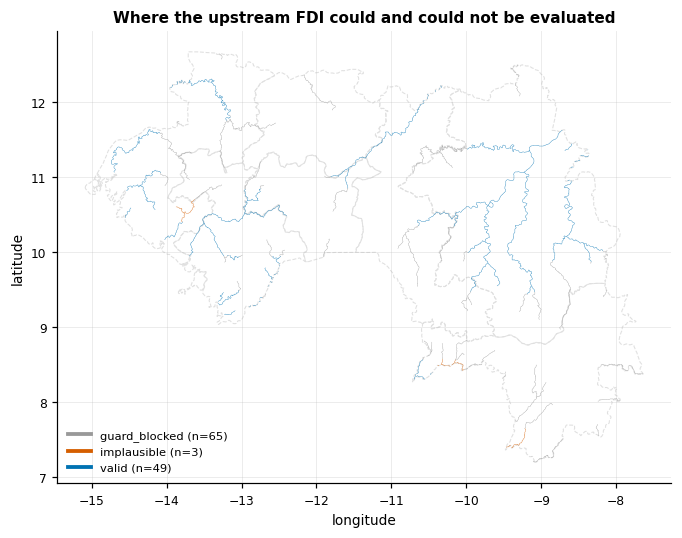

In [8]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from plasticwaste_tool import figstyle as FS
FS.use()

tiles = gpd.read_file(RIV / "guinea_river_corridor_tiles.geojson")
_adm_path = ROOT / "data" / "geoBoundaries-GIN-ADM1.geojson"
adm = gpd.read_file(_adm_path) if _adm_path.exists() else None

# The tile layer is keyed by grid position ("10428478_16_24") while results are
# keyed by run id ("river_10428478_t01"). river_aois.json carries both, so it
# is the join table. Merging the two layers directly matches nothing, and
# would silently produce a map showing every tile as unassessed -- which is
# why the assertion below exists rather than trusting the join.
aois = json.loads((RIV / "river_aois.json").read_text(encoding="utf-8"))["aois"]
tiles["aoi"] = tiles["tile_key"].map({a["tile_key"]: k for k, a in aois.items()})

t = tiles.merge(r[["aoi", "verdict", "n_patches"]], on="aoi", how="left")
# A tile with no result row is not the same as one the guard refused: one
# errored out (a missing CRS on export), the other was a deliberate decision.
# Folding them together would overstate the guard's reach by one tile.
t["verdict"] = t["verdict"].fillna("failed")
assert t["verdict"].isin(["valid"]).any(), "join produced no assessed tiles"

COLOURS = {**FS.VERDICT_COLOURS, "failed": FS.OKABE_ITO["purple"]}

fig, ax = plt.subplots(figsize=(7.2, 7.6))
if adm is not None:
    # Dashed and very light: guard_blocked tiles are grey too, and a solid
    # grey boundary would be read as another river.
    adm.boundary.plot(ax=ax, color="0.88", linewidth=0.7, linestyle="--",
                      zorder=0)

# GeoPandas line plots do not register a legend label, so the legend is built
# from proxy artists -- otherwise it silently comes out empty.
handles = []
for vd in ["guard_blocked", "failed", "no_water_mask", "implausible", "valid"]:
    sub = t[t["verdict"] == vd]
    if not len(sub):
        continue
    sub.plot(ax=ax, color=COLOURS[vd], linewidth=2.0, zorder=2)
    handles.append(Line2D([], [], color=COLOURS[vd], linewidth=2.5,
                          label=f"{vd} (n={len(sub)})"))

hit = t[t["n_patches"].fillna(0) > 0]
if len(hit):
    cent = hit.geometry.centroid
    ax.scatter(cent.x, cent.y, s=hit["n_patches"] * 14, facecolor="none",
               edgecolor="black", linewidth=1.4, zorder=3)
    handles.append(Line2D([], [], marker="o", linestyle="none",
                          markerfacecolor="none", markeredgecolor="black",
                          markersize=9,
                          label=r"tile with FDI patches (area $\propto$ count)"))

ax.set_title("Where the upstream FDI could and could not be evaluated")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.legend(handles=handles, loc="lower left", fontsize=7.5)
ax.set_aspect("equal")
FS.save(fig, "river_01_coverage_map",
        f"River corridor tiles by evaluation verdict. Only tiles in blue carry "
        f"a usable threshold; the {int(v['n_patches'].sum())} published patches "
        f"occur in {int((v['n_patches'] > 0).sum())} tiles on "
        f"{v[v['n_patches'] > 0]['main_riv'].nunique()} river systems. Grey "
        f"tiles were refused by the water-population guard and are NOT "
        f"evidence of clean water.")
plt.show()


saved  manual_qa\figures\river_02_threshold_vs_coastal.png
caption: Detection thresholds derived per tile, against the Conakry coastal reference (0.0680). The river median is 1.2 times the coastal value: a corridor's water population is mixed with turbid, shallow and bank-adjacent pixels, which inflates sigma and raises the bar debris must clear, so a low patch count upstream measures reduced sensitivity, not a clean river.


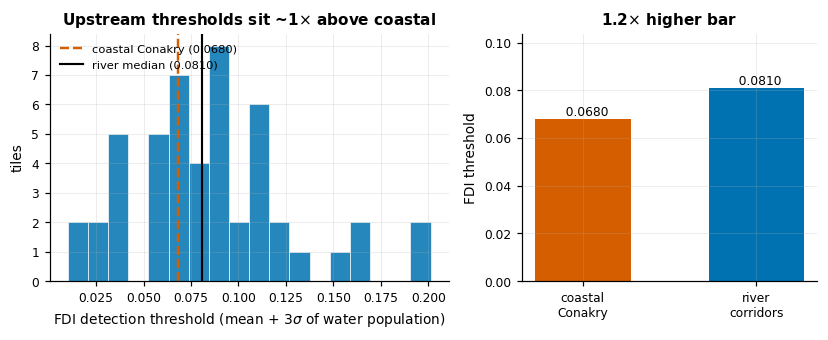

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.3),
                         gridspec_kw={"width_ratios": [1.35, 1]})

ax = axes[0]
ax.hist(v["threshold_fdi"], bins=18, color=FS.OKABE_ITO["blue"],
        alpha=0.85, edgecolor="white", linewidth=0.5)
ax.axvline(COASTAL_REF, color=FS.OKABE_ITO["vermillion"], linestyle="--",
           linewidth=1.6, label=f"coastal Conakry ({COASTAL_REF:.4f})")
ax.axvline(v["threshold_fdi"].median(), color=FS.OKABE_ITO["black"],
           linewidth=1.4, label=f"river median ({v['threshold_fdi'].median():.4f})")
ax.set_xlabel("FDI detection threshold (mean + 3$\\sigma$ of water population)")
ax.set_ylabel("tiles")
ax.set_title(f"Upstream thresholds sit ~{RATIO:.0f}$\\times$ "
             f"{'above' if RATIO >= 1 else 'below'} coastal")
ax.legend(loc="upper left", fontsize=7.5)

ax = axes[1]
ratio = RATIO
ax.bar(["coastal\nConakry", "river\ncorridors"], [COASTAL_REF, v["threshold_fdi"].median()],
       color=[FS.OKABE_ITO["vermillion"], FS.OKABE_ITO["blue"]], width=0.55)
ax.set_ylabel("FDI threshold")
ax.set_title(f"{ratio:.1f}$\\times$ higher bar")
for i, val in enumerate([COASTAL_REF, v["threshold_fdi"].median()]):
    ax.text(i, val, f"  {val:.4f}", ha="center", va="bottom", fontsize=8)
ax.set_ylim(0, v["threshold_fdi"].median() * 1.28)

fig.suptitle("")
fig.tight_layout()
FS.save(fig, "river_02_threshold_vs_coastal",
        f"Detection thresholds derived per tile, against the Conakry coastal "
        f"reference ({COASTAL_REF:.4f}). The river median is {RATIO:.1f} times "
        f"the coastal value: a corridor's water population is mixed with turbid, "
        f"shallow and bank-adjacent pixels, which inflates sigma and raises the "
        f"bar debris must clear, so a low patch count upstream measures reduced "
        f"sensitivity, not a clean river.")
plt.show()

In [10]:
from scipy.stats import mannwhitneyu, spearmanr

fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.3))

ax = axes[0]
hasp = v[v["n_patches"] > 0]; nop = v[v["n_patches"] == 0]
if hasp.empty or nop.empty:
    # The comparison needs tiles with AND without patches. With the debris
    # classifier on, the assessed corridors can return none at all.
    print(f"{len(hasp)} assessed tiles with published patches, {len(nop)} without: "
          "no comparison of water area or threshold between the two is possible.")
    plt.close(fig)
else:
    ax.scatter(nop["water_px"], nop["n_patches"], s=26, alpha=0.65,
               color=FS.OKABE_ITO["grey"], label=f"no patches (n={len(nop)})")
    ax.scatter(hasp["water_px"], hasp["n_patches"], s=60,
               color=FS.OKABE_ITO["blue"], edgecolor="black", linewidth=0.7,
               label=f"patches found (n={len(hasp)})", zorder=3)
    ax.set_xscale("log")
    ax.set_xlabel("water pixels in tile (log scale)")
    ax.set_ylabel("FDI patches detected")
    rho, p = spearmanr(v["water_px"], v["n_patches"])
    ax.set_title(f"Observable water area drives detection\n$\\rho$={rho:.2f}, P={p:.4f}")
    ax.legend(loc="upper left", fontsize=7.5)

    ax = axes[1]
    data = [nop["threshold_fdi"], hasp["threshold_fdi"]]
    bp = ax.boxplot(data, labels=["no patches", "patches found"],
                    widths=0.5, patch_artist=True, medianprops=dict(color="black"))
    for patch, c in zip(bp["boxes"], [FS.OKABE_ITO["grey"], FS.OKABE_ITO["blue"]]):
        patch.set_facecolor(c); patch.set_alpha(0.8)
    u = mannwhitneyu(hasp["threshold_fdi"], nop["threshold_fdi"])
    ax.set_ylabel("FDI threshold")
    ax.set_title(("Threshold does NOT drive it" if u.pvalue >= 0.05 else "Threshold differs")
                 + f"\nMann-Whitney P={u.pvalue:.2f}")

    fig.tight_layout()
    FS.save(fig, "river_03_what_drives_detection",
            f"Left: patch counts against the observable water area of a tile "
            f"(Spearman rho={rho:.2f}, P={p:.4f}); tiles with detections hold "
            f"{hasp['water_px'].median() / max(nop['water_px'].median(), 1):.1f} times "
            f"the median water pixels of those without. Right: the detection "
            f"threshold "
            + ("does not differ significantly" if u.pvalue >= 0.05 else "differs")
            + f" between the two groups (Mann-Whitney P={u.pvalue:.2f}).")
    plt.show()

0 assessed tiles with published patches, 49 without: no comparison of water area or threshold between the two is possible.


saved  manual_qa\figures\river_04_length_accounting.png
caption: Disposition of Guinea's 5,972 km of screened river corridor. 55% carries a usable FDI threshold. The rest is reported as NOT ASSESSED rather than as zero detections, because WorldCover does not map enough permanent water in those reaches to estimate a threshold from.


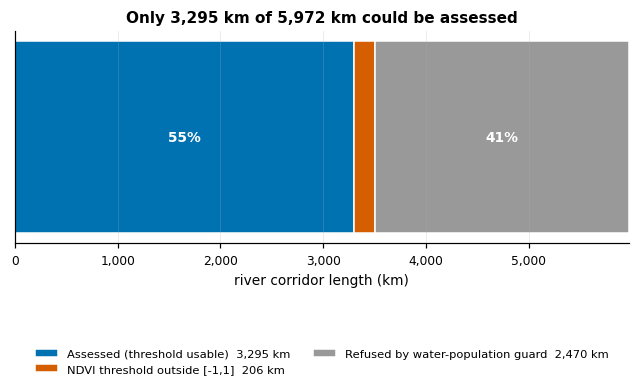

In [11]:
fig, ax = plt.subplots(figsize=(7.2, 2.5))

order = ["valid", "no_water_mask", "implausible", "guard_blocked"]
labels = {"valid": "Assessed (threshold usable)",
          "no_water_mask": "No water mask returned",
          "implausible": "NDVI threshold outside [-1,1]",
          "guard_blocked": "Refused by water-population guard"}
left = 0.0
total = r["length_km"].sum()
for vd in order:
    km = r.loc[r["verdict"] == vd, "length_km"].sum()
    if km <= 0:
        continue
    ax.barh(0, km, left=left, height=0.55, color=FS.VERDICT_COLOURS[vd],
            edgecolor="white", linewidth=1.0, label=f"{labels[vd]}  {km:,.0f} km")
    if km / total > 0.05:
        ax.text(left + km / 2, 0, f"{km / total:.0%}", ha="center", va="center",
                color="white", fontweight="bold", fontsize=9)
    left += km

ax.set_yticks([]); ax.set_xlim(0, total)
ax.set_xlabel("river corridor length (km)")
ax.set_title(f"Only {r.loc[r.verdict == 'valid', 'length_km'].sum():,.0f} km "
             f"of {total:,.0f} km could be assessed")
FS.thousands(ax, "x")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=2, fontsize=7.5)
ax.grid(axis="y", visible=False)

FS.save(fig, "river_04_length_accounting",
        f"Disposition of Guinea's {total:,.0f} km of screened river corridor. "
        f"{r.loc[r.verdict == 'valid', 'length_km'].sum() / total:.0%} carries a "
        f"usable FDI threshold. The rest is reported as NOT ASSESSED rather than "
        f"as zero detections, because WorldCover does not map enough permanent "
        f"water in those reaches to estimate a threshold from.")
plt.show()

## 6. What to carry into the layer and the methodology

**One layer, not two.** Coastal and river patches go into the same FDI layer — a user selecting an area
sees whatever is there. Every patch carries its `region` / `aoi` and its `threshold_fdi`, because the
thresholds are per-AOI by construction.

**Three things the interface must not get wrong:**

1. **NOT ASSESSED ≠ no debris.** Tiles below the pixel floor could not be looked at. Render them as
   *not assessed*, never as a clean river.
2. **A zero on an assessed tile is a statement about sensitivity as well as debris.** River thresholds
   run 1.2× the coastal one (median 0.081 against Conakry's 0.068): bank-adjacent, shallow and turbid
   pixels widen the water population and raise the bar debris must clear. January 2024's zero is
   reported as *no detection at this sensitivity*, not as a clean river.
3. **The layer does not measure plastic.** The MARIDA classifier removes the vegetation, Sargassum and
   foam the rule alone responds to, but what it keeps is floating debris, not plastic specifically. On
   rivers **water hyacinth** (endemic in West African rivers) and sediment plumes are the confusers to
   name. The column is `floating_debris_score`; do not rename it.

**Coverage is bounded by the water product, not by the method.** State the assessable fraction of
river length (55% assessed; 74% passes preflight), not just the number of systems.

**Thresholds are per tile, not per river system** (section 1). State this plainly rather than implying
a system-level threshold that was not computed.